# Assignment Problems: Day 14

The following problems require access to the file named ‘Dataset_Day14.csv’, provided with this assignment.


This is the Iris dataset with150 data points (same dataset as Day 13)


It includes three iris species with 50 samples each as well as some properties about each flower. One flower species is linearly separable from the other two, but the other two are not linearly separable from each other.

The columns in this dataset are: Id, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score

* Treat outliers and missing values if present and scale the data.

In [2]:
data = pd.read_csv("Dataset_Day14.csv")
data.drop("Id", axis = 1, inplace = True)
scaled = pd.DataFrame()
for i in ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']:
    scaled[i] = (data[i]-data[i].mean())/data[i].std()
outlier = pd.DataFrame(columns = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'])
outlier = scaled[(scaled["SepalLengthCm"]>3)|(scaled["SepalLengthCm"]<-3)|
                 (scaled["SepalWidthCm"]>3)|(scaled["SepalWidthCm"]<-3)|
                 (scaled["PetalLengthCm"]>3)|(scaled["PetalLengthCm"]<-3)|
                 (scaled["PetalWidthCm"]>3)|(scaled["PetalWidthCm"]<-3)]
d = scaled.drop(outlier.index, axis=0)
data.drop(outlier.index, axis=0, inplace = True)
d.reset_index(inplace = True, drop = True)
data.reset_index(inplace = True, drop = True)
print("\nno. of Outlier", len(outlier), "\n% of Outlier = ", len(outlier)/len(data)*100)
d.info(), d.describe()


no. of Outlier 1 
% of Outlier =  0.6711409395973155
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  149 non-null    float64
 1   SepalWidthCm   149 non-null    float64
 2   PetalLengthCm  149 non-null    float64
 3   PetalWidthCm   149 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


(None,
        SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
 count     149.000000    149.000000     149.000000    149.000000
 mean        0.001162     -0.020834       0.008591      0.007024
 std         1.003271      0.970159       0.997803      0.999653
 min        -1.863780     -2.430844      -1.563497     -1.439627
 25%        -0.897674     -0.585801      -1.223442     -1.177559
 50%        -0.052331     -0.124540       0.363481      0.132781
 75%         0.672249      0.567351       0.760212      0.787951
 max         2.483699      2.643024       1.780377      1.705189)

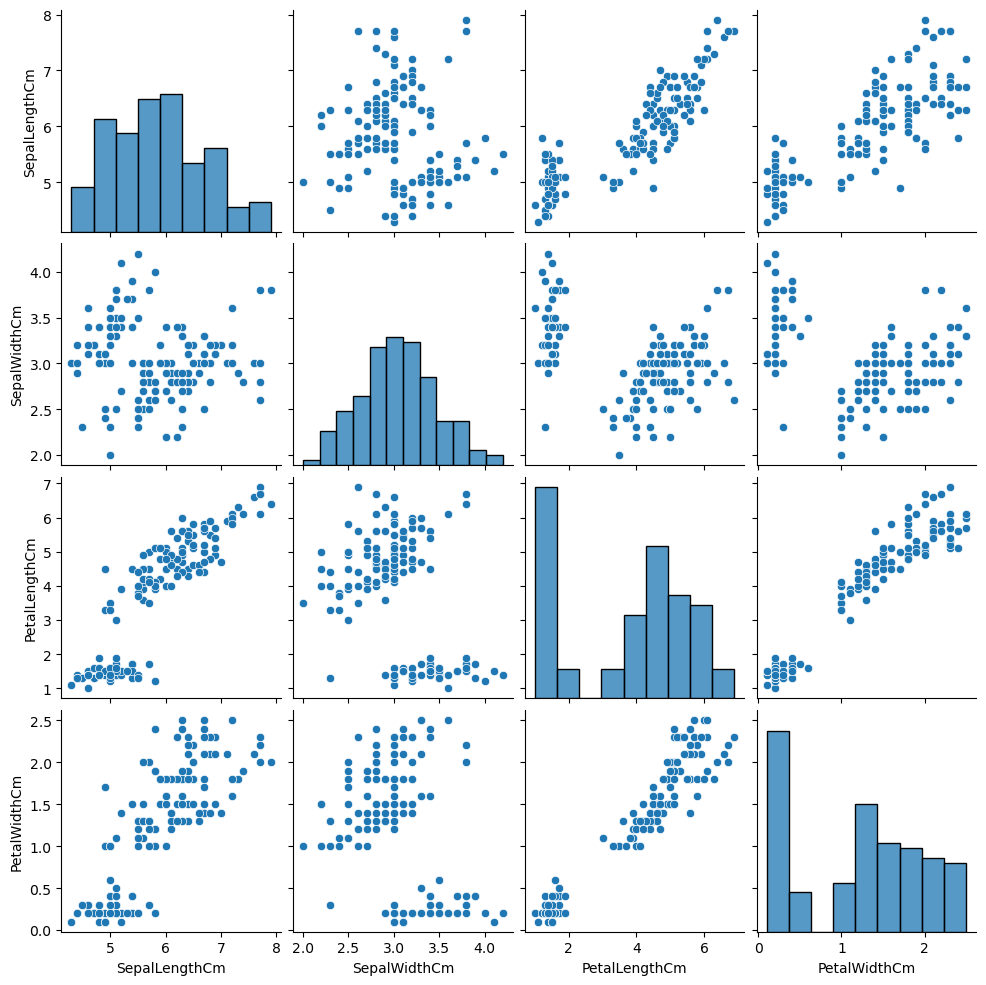

In [3]:
sns.pairplot(data)

* Fit the DBSCAN clusters for the default parameter values and also show the Species distribution in each of the default clusters.

In [4]:
model = DBSCAN().fit(d)
clusters = model.labels_
display(pd.DataFrame(clusters).value_counts()/len(d)*100)

 1    47.651007
 0    29.530201
-1    22.818792
dtype: float64

* Use nearest neighbour algorithm to find the most optimal value of ‘eps’ parameter.

 1    61.073826
 0    31.543624
-1     7.382550
dtype: float64

Species        
Iris-versicolor    33.557047
Iris-virginica     33.557047
Iris-setosa        32.885906
dtype: float64

Accuracy =  65.77181208053692


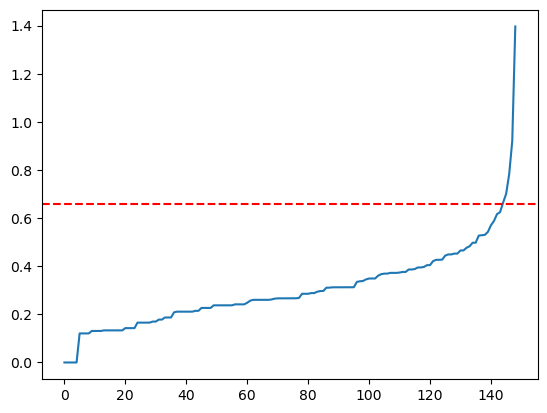

In [5]:
n = NearestNeighbors().fit(d)
dist, ind = n.kneighbors(d)
dist = np.sort(dist,axis=0)[:,1]
plt.plot(dist)
plt.axhline(y=0.66, color='r', ls="--")

model = DBSCAN(eps = 0.66).fit(d)
clusters = model.labels_
display(pd.DataFrame(clusters).value_counts()/len(d)*100)
display(pd.DataFrame(data['Species']).value_counts()/len(d)*100)
pred = pd.DataFrame({"species":clusters})
test = pd.DataFrame(columns = ["species"])
for i in data["Species"]:
    if i == "Iris-setosa":
        test = pd.concat([test, pd.DataFrame([0], columns=pred.columns)], ignore_index=True)
    elif i == "Iris-virginica":
        test = pd.concat([test, pd.DataFrame([-1], columns=pred.columns)], ignore_index=True)
    else:
        test = pd.concat([test, pd.DataFrame([1], columns=pred.columns)], ignore_index=True)
a = 0
for i in range(0,len(d)):
    if pred["species"][i] == test["species"][i]:
        a = a + 1
a = (a/len(d))*100
print("Accuracy = ", a)

* Use the ‘eps’ value in (2.) and find the most optimal value of ‘min_samples’ using silhouette score.

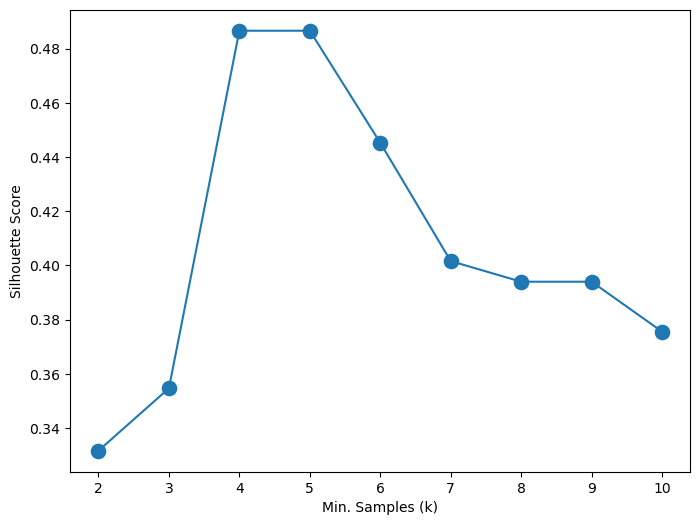

In [6]:
ss = []
for k in range(2, 11):
    model = DBSCAN(eps = 0.66, min_samples=k).fit(d)
    ss.append(silhouette_score(d, model.labels_))

ss_series = pd.Series(ss, index = range(2, 11))

plt.figure(figsize=(8, 6))
ax = sns.lineplot(y = ss_series, x = ss_series.index)
ax = sns.scatterplot(y = ss_series, x = ss_series.index, s = 150)
ax = ax.set(xlabel = 'Min. Samples (k)', 
            ylabel = 'Silhouette Score')

In [38]:
model = DBSCAN(eps = 0.65).fit(d)
clusters = model.labels_
display(pd.DataFrame(clusters).value_counts()/len(d)*100)
display(pd.DataFrame(data['Species']).value_counts()/len(d)*100)

 1    60.402685
 0    30.872483
-1     8.724832
dtype: float64

Species        
Iris-versicolor    33.557047
Iris-virginica     33.557047
Iris-setosa        32.885906
dtype: float64

* Find all the outliers using the DBSCAN algorithm.

In [78]:
model = DBSCAN(eps = 0.47).fit(d)
clusters = model.labels_
display(pd.DataFrame(clusters).value_counts()/len(d)*100)
display(pd.DataFrame(data['Species']).value_counts()/len(d)*100)
outliers = pd.DataFrame({"species":clusters})
outliers = outliers[outliers["species"] == 2]
print(outliers)
dfs = data.drop(outliers.index, axis=0)
df = d.drop(outliers.index, axis=0)
df.reset_index(inplace = True, drop = True)
dfs.reset_index(inplace = True, drop = True)

 1    30.201342
-1    29.530201
 0    29.530201
 2    10.738255
dtype: float64

Species        
Iris-versicolor    33.557047
Iris-virginica     33.557047
Iris-setosa        32.885906
dtype: float64

     species
101        2
102        2
103        2
109        2
111        2
115        2
119        2
123        2
136        2
138        2
139        2
140        2
142        2
143        2
144        2
146        2


 1    33.834586
-1    33.082707
 0    33.082707
dtype: float64

Species        
Iris-versicolor    33.557047
Iris-setosa        32.885906
Iris-virginica     22.818792
dtype: float64

Accuracy =  66.9172932330827


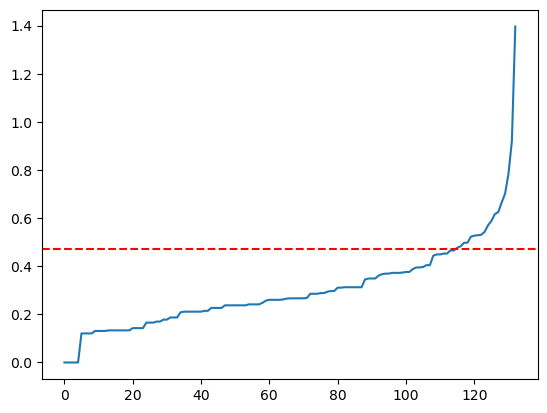

In [80]:
n = NearestNeighbors().fit(df)
dist, ind = n.kneighbors(df)
dist = np.sort(dist,axis=0)[:,1]
plt.plot(dist)
plt.axhline(y=0.47, color='r', ls="--")

model = DBSCAN(eps = 0.47).fit(df)
clusters = model.labels_
display(pd.DataFrame(clusters).value_counts()/len(df)*100)
display(pd.DataFrame(dfs['Species']).value_counts()/len(d)*100)
pred = pd.DataFrame({"species":clusters})
test = pd.DataFrame(columns = ["species"])
for i in dfs["Species"]:
    if i == "Iris-setosa":
        test = pd.concat([test, pd.DataFrame([0], columns=pred.columns)], ignore_index=True)
    elif i == "Iris-virginica":
        test = pd.concat([test, pd.DataFrame([1], columns=pred.columns)], ignore_index=True)
    else:
        test = pd.concat([test, pd.DataFrame([1], columns=pred.columns)], ignore_index=True)
a = 0
for i in range(0,len(df)):
    if pred["species"][i] == test["species"][i]:
        a = a + 1
a = (a/len(df))*100
print("Accuracy = ", a)

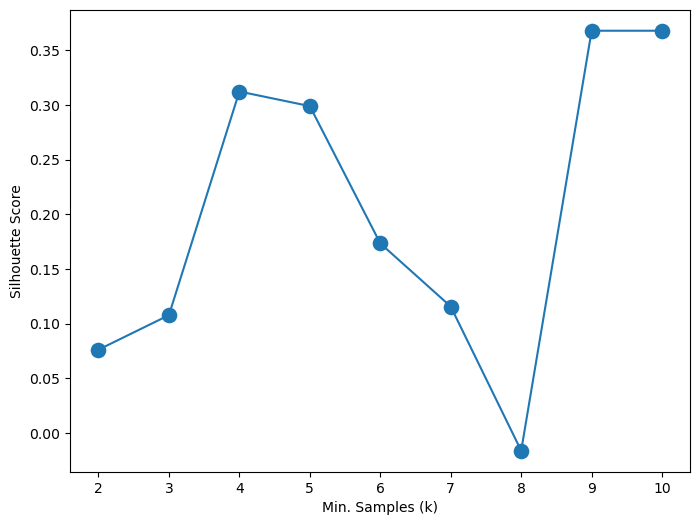

In [81]:
ss = []
for k in range(2, 11):
    model = DBSCAN(eps = 0.47, min_samples=k).fit(df)
    ss.append(silhouette_score(df, model.labels_))

ss_series = pd.Series(ss, index = range(2, 11))

plt.figure(figsize=(8, 6))
ax = sns.lineplot(y = ss_series, x = ss_series.index)
ax = sns.scatterplot(y = ss_series, x = ss_series.index, s = 150)
ax = ax.set(xlabel = 'Min. Samples (k)', 
            ylabel = 'Silhouette Score')

In [91]:
model = DBSCAN(eps = 0.45, min_samples = 4).fit(df)
clusters = model.labels_
display(pd.DataFrame(clusters).value_counts()/len(df)*100)
display(pd.DataFrame(dfs['Species']).value_counts()/len(d)*100)
pred = pd.DataFrame({"species":clusters})
test = pd.DataFrame(columns = ["species"])
for i in dfs["Species"]:
    if i == "Iris-setosa":
        test = pd.concat([test, pd.DataFrame([0], columns=pred.columns)], ignore_index=True)
    elif i == "Iris-virginica":
        test = pd.concat([test, pd.DataFrame([-1], columns=pred.columns)], ignore_index=True)
    else:
        test = pd.concat([test, pd.DataFrame([1], columns=pred.columns)], ignore_index=True)
a = 0
for i in range(0,len(df)):
    if pred["species"][i] == test["species"][i]:
        a = a + 1
a = (a/len(df))*100
print("Accuracy = ", a)

-1    36.842105
 0    33.082707
 1    30.075188
dtype: float64

Species        
Iris-versicolor    33.557047
Iris-setosa        32.885906
Iris-virginica     22.818792
dtype: float64

Accuracy =  85.71428571428571


Name - Nikhil Khatri

SIC - 21BCSA92